# Constraint and Probability-Distribution Validation

This notebook validates the implemented demographic and behavioural constraints.

**dataset distribution → expected distribution → framework output**

A PASS requires the framework output to match the expected distribution within an absolute tolerance of `1e-8`. The notebook validates every  representative profile through its exact combination of output-relevant attributes; identical combinations are executed once and the result is assigned back to every matching row.

## Validation groups and expected outcomes

| Validation group | Constraint condition | Expected outcome |
|---|---|---|
| Profiles without profile-specific constraints | No profile-specific constraint condition is met | The trip-purpose distribution matches the original NTS0611a distribution. |
| Profiles with trip-purpose constraints | `Industry = Does not apply` | `Commuting` and `Business` are removed; remaining probabilities are renormalised. |
| Profiles with trip-purpose constraints | Distance travelled to work = `Works mainly from home` | `Commuting` is removed; remaining probabilities are renormalised. |
| Profiles with travel-mode constraints | Age is `0–4` or `5–11` | `Car or van driver` and `Motorcycle` are removed; remaining probabilities are renormalised. |
| Profiles with travel-mode constraints | Car ownership = 'No cars or vans in household' | `Car or van driver` and `Car or van passenger` are removed; remaining probabilities are renormalised. |
| Profiles with multiple profile-specific constraints | More than one profile-specific constraint condition is met | All applicable removals are applied together and remaining probabilities are renormalised. |

**Study-area condition.** For the Manchester case study, `Bus in London` and `London Underground` are removed from the travel-mode distributions of all profiles, and remaining probabilities are renormalised.

**Unaffected distribution.** Start-time distributions are not modified by any implemented constraint and must match the original NTS0502b distribution for every retained trip purpose.

The rule-level groups can overlap. For example, a young profile can also have `Industry = Does not apply`. Exact constraint combinations are therefore recorded separately and used for exhaustive row coverage.

## AI Collaboration Record

**Human author and reviewer:** Peter Jiang  
**AI tool:** OpenAI Codex  
**Date:** 17 August 2026  
**Scope:** Notebook structure, Python implementation, validation logic, plots, code comments and documentation.  
**Human responsibility:** Review the rules against the dissertation methodology and repository, run the notebook on the final project outputs, inspect failures and figures, and approve the interpretation used in the dissertation.

### Consolidated prompt

> Create a new Jupyter notebook for the mobility-modelling framework that validates every retained representative profile against the implemented constraints. Use the following validation groups: profiles without profile-specific constraints; profiles where Industry equals Does not apply; profiles working mainly from home; young profiles aged 0–4 or 5–11; profiles with no household car; and profiles with multiple profile-specific constraints. Apply the Manchester study-area removal of Bus in London and London Underground to every profile. Validate three distribution types: NTS0611a trip purpose, NTS0502b start time and NTS0409a travel mode. For each unique output-relevant input combination, independently calculate the expected distribution without calling the framework constraint functions, execute the framework, compare categories and probabilities within an absolute tolerance of 1e-8, confirm valid probability sums, and assign the result back to all matching profile rows. Produce concise summary and failure tables plus four figures: constraint-count coverage, a baseline comparison, individual constraint comparisons and a multiple-constraint comparison. Include clear Markdown documentation and an AI Collaboration Record in every AI-generated code cell.

This consolidated English prompt records the requirements developed through the preceding Chinese-language dissertation discussion; it is not presented as a verbatim single-message quotation.

## 1. Imports and configuration

Run this notebook from `notebooks/validation`. The profile-space path and validation-output directory can be overridden with the environment variables `PROFILE_SPACE_PATH` and `VALIDATION_OUTPUT_DIR` when required.

In [15]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd


TOLERANCE = 1e-8

project_root = Path.cwd().parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

profile_space_path = Path(
    os.environ.get(
        "PROFILE_SPACE_PATH",
        project_root
        / "output"
        / "representative_profiles"
        / "constrained_representative_profile_space.parquet",
    )
)

harmonised_nts_directory = (
    project_root / "data" / "nts" / "harmonised"
)

validation_output_directory = Path(
    os.environ.get(
        "VALIDATION_OUTPUT_DIR",
        project_root
        / "output"
        / "validation"
        / "constraint_distribution_validation",
    )
)
figure_output_directory = validation_output_directory / "figures"

validation_output_directory.mkdir(parents=True, exist_ok=True)
figure_output_directory.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Profile-space input:", profile_space_path)
print("Validation output:", validation_output_directory)

Project root: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework
Profile-space input: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\representative_profiles\constrained_representative_profile_space.parquet
Validation output: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\constraint_distribution_validation


## 2. Load current framework inputs

The notebook reads the current constrained profile-space output rather than using a hard-coded row count. Run the upstream construction notebooks first if the Parquet file is missing.

In [2]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Load the current constrained profile space and the three harmonised NTS source tables, then import the framework integration function.

required_paths = {
    "Constrained representative profile space": profile_space_path,
    "NTS0611a": (
        harmonised_nts_directory
        / "nts0611a_trip_purpose_probability.json"
    ),
    "NTS0502b": (
        harmonised_nts_directory
        / "nts0502b_temporal_pattern_probability.json"
    ),
    "NTS0409a": (
        harmonised_nts_directory
        / "nts0409a_travel_mode_probability.json"
    ),
}

missing_paths = [
    f"{name}: {path}"
    for name, path in required_paths.items()
    if not path.exists()
]
if missing_paths:
    raise FileNotFoundError(
        "Run the upstream construction notebooks before this validation:\n"
        + "\n".join(missing_paths)
    )

representative_profile_space = pd.read_parquet(profile_space_path)
nts0611_df = pd.read_json(required_paths["NTS0611a"])
nts0502_df = pd.read_json(required_paths["NTS0502b"])
nts0409_df = pd.read_json(required_paths["NTS0409a"])

from ontology.NTS_TRIP_PURPOSE_MAPPING import NTS_TRIP_PURPOSE_MAPPING
from ontology.STUDY_AREA import STUDY_AREA
from src.demographic_behaviour_layers_integration import (
    DEMOGRAPHIC_ATTRIBUTES,
    construct_constrained_behaviour_representation,
)

print(
    "Retained representative profiles loaded:",
    f"{len(representative_profile_space):,}",
)
print("Configured study area:", STUDY_AREA)

Retained representative profiles loaded: 2,147,608
Configured study area: Manchester


## 3. Assemble framework-ready behavioural evidence

The framework-ready evidence is assembled from the three harmonised source tables in memory. The validation still constructs all expected constraint outcomes independently in Section 6.

In [3]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Assemble the harmonised NTS tables into the evidence structure required by the framework integration function.

PURPOSE_EVIDENCE_KEY = "nts0611a_trip_purpose_distribution"
TIME_EVIDENCE_KEY = "nts0502b_temporal_distribution"
MODE_EVIDENCE_KEY = "nts0409a_travel_mode_distribution"

trip_purpose_categories = [
    column
    for column in nts0611_df.columns
    if column not in {"Year", "Sex", "Age"}
]

assembled_behavioural_evidence = {}

for purpose in trip_purpose_categories:
    mapping = NTS_TRIP_PURPOSE_MAPPING[purpose]
    temporal_purpose = mapping["nts0502b"][0]
    mode_purpose = mapping["nts0409a"][0]

    temporal_records = nts0502_df.loc[
        nts0502_df["Trip purpose"].eq(temporal_purpose)
    ]
    mode_records = nts0409_df.loc[
        nts0409_df["Purpose"].eq(mode_purpose)
    ]

    if len(temporal_records) != 1 or len(mode_records) != 1:
        raise ValueError(
            f"Expected one NTS0502b and one NTS0409a source row "
            f"for framework purpose '{purpose}'."
        )

    purpose_records = (
        nts0611_df[["Year", "Sex", "Age", purpose]]
        .rename(columns={purpose: "Trip Purpose Probability"})
        .to_dict(orient="records")
    )

    assembled_behavioural_evidence[purpose] = {
        PURPOSE_EVIDENCE_KEY: purpose_records,
        TIME_EVIDENCE_KEY: temporal_records.to_dict(
            orient="records"
        ),
        MODE_EVIDENCE_KEY: mode_records.to_dict(
            orient="records"
        ),
    }

assert set(assembled_behavioural_evidence) == set(
    trip_purpose_categories
)

print(
    "Framework trip purposes assembled:",
    len(assembled_behavioural_evidence),
)

Framework trip purposes assembled: 14


## 4. Demographic constraint validation

This preliminary check validates the two demographic constraints reported in the methodology:

1. every retained row has a non-zero value in all eight source-count columns; and
2. employed and non-employed profiles use the required Industry and Distance-to-work values.

The check validates the already constructed profile space; it does not reconstruct it.

In [4]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Check every retained row against the zero-count and employment constraints and report any violations.

COUNT_COLUMNS = [
    "Age Population",
    "Sex Population",
    "Household Count",
    "Economic Count",
    "Industry Count",
    "Ethnic Count",
    "Travel Distance Count",
    "Car Ownership Count",
]

EMPLOYED_PROFILES = {
    "Economically active (excluding full-time students): In employment",
    "Economically active and a full-time student: In employment",
}
DOES_NOT_APPLY = "Does not apply"

missing_profile_columns = sorted(
    set(DEMOGRAPHIC_ATTRIBUTES + tuple(COUNT_COLUMNS))
    - set(representative_profile_space.columns)
)
if missing_profile_columns:
    raise KeyError(
        "Profile space is missing required columns: "
        f"{missing_profile_columns}"
    )

zero_count_violation = ~(
    representative_profile_space[COUNT_COLUMNS]
    .notna()
    .all(axis=1)
    & representative_profile_space[COUNT_COLUMNS]
    .gt(0)
    .all(axis=1)
)

is_employed = representative_profile_space[
    "Economic Activity Status"
].isin(EMPLOYED_PROFILES)
industry_applies = representative_profile_space["Industry"].ne(
    DOES_NOT_APPLY
)
work_distance_applies = representative_profile_space[
    "Distance travelled to work"
].ne(DOES_NOT_APPLY)

employment_constraint_passed = (
    is_employed & industry_applies & work_distance_applies
) | (
    ~is_employed & ~industry_applies & ~work_distance_applies
)
employment_violation = ~employment_constraint_passed

demographic_validation_summary = pd.DataFrame(
    [
        {
            "Demographic check": "Zero-count constraint",
            "Rows checked": len(representative_profile_space),
            "Violations": int(zero_count_violation.sum()),
        },
        {
            "Demographic check": "Employment constraint",
            "Rows checked": len(representative_profile_space),
            "Violations": int(employment_violation.sum()),
        },
    ]
)
demographic_validation_summary["Result"] = np.where(
    demographic_validation_summary["Violations"].eq(0),
    "PASS",
    "FAIL",
)

display(demographic_validation_summary)

if demographic_validation_summary["Result"].eq("FAIL").any():
    raise AssertionError(
        "The imported profile space violates one or more reported "
        "demographic constraints."
    )

,Demographic check,Rows checked,Violations,Result
0,Zero-count constraint,2147608,0,PASS
1,Employment constraint,2147608,0,PASS


## 5. Identify the constraints triggered by every profile

The four profile-specific conditions are recorded independently. Rule-level coverage can overlap, while the exact triggered-rule combination provides one unambiguous behavioural validation case for each row. The Manchester study-area condition is global and is not included in the profile-specific constraint count.

In [5]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Tag every retained profile with its applicable behavioural rules, count rule coverage and create exact output-relevant cases.

YOUNG_AGES = {"0-4", "5-11"}
NO_HOUSEHOLD_CAR = "No cars or vans in household"

profile_validation = pd.DataFrame(
    index=representative_profile_space.index
)
profile_validation["Profile Row Position"] = np.arange(
    len(representative_profile_space),
    dtype=np.int64,
)
profile_validation["Age"] = representative_profile_space["Age"]
profile_validation["Sex"] = representative_profile_space["Sex"]
profile_validation["Industry constraint"] = (
    representative_profile_space["Industry"].eq(DOES_NOT_APPLY)
)
profile_validation["WFH constraint"] = (
    representative_profile_space[
        "Distance travelled to work"
    ].eq("Works mainly from home")
)
profile_validation["Young-age constraint"] = (
    representative_profile_space["Age"].isin(YOUNG_AGES)
)
profile_validation["No-car constraint"] = (
    representative_profile_space["Car Ownership"].eq(
        NO_HOUSEHOLD_CAR
    )
)

rule_columns = [
    "Industry constraint",
    "WFH constraint",
    "Young-age constraint",
    "No-car constraint",
]
profile_validation["Profile-specific constraint count"] = (
    profile_validation[rule_columns].sum(axis=1).astype("int8")
)

constraint_labels = pd.Series(
    "",
    index=profile_validation.index,
    dtype="string",
)
for rule_column, rule_label in {
    "Industry constraint": "Industry does not apply",
    "WFH constraint": "Works mainly from home",
    "Young-age constraint": "Young age",
    "No-car constraint": "No household car",
}.items():
    applies = profile_validation[rule_column]
    separator = constraint_labels.ne("").map(
        {True: " + ", False: ""}
    )
    constraint_labels = constraint_labels + np.where(
        applies,
        separator + rule_label,
        "",
    )

profile_validation["Constraint combination"] = (
    constraint_labels.replace(
        "",
        "No profile-specific constraint",
    )
)

case_columns = ["Age", "Sex", *rule_columns]
profile_validation["Validation case"] = (
    profile_validation.groupby(
        case_columns,
        sort=False,
        dropna=False,
    ).ngroup()
)

condition_masks = {
    "No profile-specific constraint": (
        profile_validation[
            "Profile-specific constraint count"
        ].eq(0)
    ),
    "Industry = Does not apply": profile_validation[
        "Industry constraint"
    ],
    "Works mainly from home": profile_validation["WFH constraint"],
    "Age is 0-4 or 5-11": profile_validation[
        "Young-age constraint"
    ],
    "No household car": profile_validation["No-car constraint"],
    "Multiple profile-specific constraints": (
        profile_validation[
            "Profile-specific constraint count"
        ].gt(1)
    ),
}

condition_coverage = pd.DataFrame(
    [
        {
            "Validation condition": name,
            "Profiles covered": int(mask.sum()),
            "Percentage of retained profiles": (
                float(mask.mean() * 100)
            ),
        }
        for name, mask in condition_masks.items()
    ]
)
condition_coverage.loc[len(condition_coverage)] = {
    "Validation condition": "Manchester study-area constraint",
    "Profiles covered": len(profile_validation),
    "Percentage of retained profiles": 100.0,
}

combination_coverage = (
    profile_validation["Constraint combination"]
    .value_counts(dropna=False)
    .rename_axis("Exact constraint combination")
    .reset_index(name="Profiles covered")
)

display(condition_coverage)
display(combination_coverage)

required_condition_names = [
    "No profile-specific constraint",
    "Industry = Does not apply",
    "Works mainly from home",
    "Age is 0-4 or 5-11",
    "No household car",
    "Multiple profile-specific constraints",
]
uncovered_conditions = condition_coverage.loc[
    condition_coverage["Validation condition"].isin(
        required_condition_names
    )
    & condition_coverage["Profiles covered"].eq(0),
    "Validation condition",
].tolist()
if uncovered_conditions:
    raise AssertionError(
        "The current profile space does not contain validation "
        f"coverage for: {uncovered_conditions}"
    )

,Validation condition,Profiles covered,Percentage of retained profiles
0,No profile-specific constraint,1357056,63.189185
1,Industry = Does not apply,36632,1.705712
2,Works mainly from home,301568,14.042041
3,Age is 0-4 or 5-11,1520,0.070776
4,No household car,536902,25.000000
5,Multiple profile-specific constraints,85690,3.990021
6,Manchester study-area constraint,2147608,100.000000


,Exact constraint combination,Profiles covered
0,No profile-specific constraint,1357056
1,No household car,452352
2,Works mainly from home,226176
3,Works mainly from home + No household car,75392
4,Industry does not apply,26334
5,Industry does not apply + No household car,8778
6,Industry does not apply + Young age,1140
7,Industry does not apply + Young age + No house...,380


## 6. Independent expected-distribution functions

These functions reproduce the documented expected outcomes without importing or calling `apply_trip_purpose_constraint` or `apply_travel_mode_constraint`. This separation avoids validating the framework with the same implementation that produced its output.

In [6]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Define independent source lookups, expected category removals, renormalisation and numerical distribution comparison helpers.

SOURCE_IDENTIFIER_COLUMNS = {
    "nts0611a": {"Year", "Sex", "Age"},
    "nts0502b": {"Year", "Trip purpose"},
    "nts0409a": {"Year", "Purpose"},
}
LONDON_MODES_FOR_VALIDATION = {
    "Bus in London",
    "London Underground",
}


def numeric_distribution(dataset_row, identifier_columns):
    probability_columns = [
        column
        for column in dataset_row.index
        if column not in identifier_columns
    ]
    return pd.to_numeric(
        dataset_row[probability_columns],
        errors="raise",
    ).astype(float)


def get_one_row(dataframe, mask, description):
    rows = dataframe.loc[mask]
    if len(rows) != 1:
        raise ValueError(
            f"Expected one source row for {description}; "
            f"found {len(rows)}."
        )
    return rows.iloc[0]


def source_trip_purpose_distribution(age, sex):
    row = get_one_row(
        nts0611_df,
        nts0611_df["Age"].eq(age)
        & nts0611_df["Sex"].eq(sex),
        f"NTS0611a age={age}, sex={sex}",
    )
    return numeric_distribution(
        row,
        SOURCE_IDENTIFIER_COLUMNS["nts0611a"],
    )


def source_time_and_mode_distributions(purpose):
    mapping = NTS_TRIP_PURPOSE_MAPPING[purpose]
    temporal_purpose = mapping["nts0502b"][0]
    mode_purpose = mapping["nts0409a"][0]

    temporal_row = get_one_row(
        nts0502_df,
        nts0502_df["Trip purpose"].eq(temporal_purpose),
        f"NTS0502b purpose={temporal_purpose}",
    )
    mode_row = get_one_row(
        nts0409_df,
        nts0409_df["Purpose"].eq(mode_purpose),
        f"NTS0409a purpose={mode_purpose}",
    )

    temporal = numeric_distribution(
        temporal_row,
        SOURCE_IDENTIFIER_COLUMNS["nts0502b"],
    )
    mode = numeric_distribution(
        mode_row,
        SOURCE_IDENTIFIER_COLUMNS["nts0409a"],
    )
    return temporal, mode


def independently_expected_purpose_removals(profile):
    if profile["Industry"] == DOES_NOT_APPLY:
        return {"Commuting", "Business"}
    if (
        profile["Distance travelled to work"]
        == "Works mainly from home"
    ):
        return {"Commuting"}
    return set()


def independently_expected_mode_removals(profile):
    removals = set()

    if STUDY_AREA.strip().casefold() != "london":
        removals.update(LONDON_MODES_FOR_VALIDATION)

    if profile["Age"] in YOUNG_AGES:
        removals.update({"Car or van driver", "Motorcycle"})

    if profile["Car Ownership"] == NO_HOUSEHOLD_CAR:
        removals.update(
            {"Car or van driver", "Car or van passenger"}
        )

    return removals


def remove_and_renormalise(source_distribution, removals):
    source_distribution = pd.Series(
        source_distribution,
        dtype=float,
    )
    missing = set(removals) - set(source_distribution.index)
    if missing:
        raise KeyError(
            "Expected removal categories are missing from the source "
            f"distribution: {sorted(missing)}"
        )

    if not removals:
        return source_distribution.copy()

    retained = source_distribution.drop(labels=list(removals))
    retained_total = float(retained.sum())
    if retained.empty or retained_total <= 0:
        raise ValueError(
            "No positive probability remains after the expected "
            "category removals."
        )
    return retained / retained_total


def compare_distributions(expected, actual):
    expected = pd.Series(expected, dtype=float)
    actual = pd.Series(actual, dtype=float)

    categories_match = set(expected.index) == set(actual.index)
    actual_aligned = actual.reindex(expected.index)

    if categories_match:
        differences = (expected - actual_aligned).abs()
        maximum_difference = (
            float(differences.max())
            if not differences.empty
            else 0.0
        )
        probabilities_match = bool(
            np.allclose(
                expected.to_numpy(dtype=float),
                actual_aligned.to_numpy(dtype=float),
                rtol=0.0,
                atol=TOLERANCE,
                equal_nan=False,
            )
        )
    else:
        maximum_difference = np.inf
        probabilities_match = False

    expected_values = expected.to_numpy(dtype=float)
    actual_values = actual.to_numpy(dtype=float)
    values_are_valid = bool(
        np.isfinite(expected_values).all()
        and np.isfinite(actual_values).all()
        and (expected_values >= 0).all()
        and (actual_values >= 0).all()
    )
    sums_are_valid = bool(
        np.isclose(
            expected.sum(),
            1.0,
            rtol=0.0,
            atol=TOLERANCE,
        )
        and np.isclose(
            actual.sum(),
            1.0,
            rtol=0.0,
            atol=TOLERANCE,
        )
    )

    return {
        "Categories match": categories_match,
        "Probabilities match": probabilities_match,
        "Values valid": values_are_valid,
        "Probability sums valid": sums_are_valid,
        "Maximum absolute difference": maximum_difference,
        "Expected probability sum": float(expected.sum()),
        "Framework probability sum": float(actual.sum()),
        "Result": (
            "PASS"
            if categories_match
            and probabilities_match
            and values_are_valid
            and sums_are_valid
            else "FAIL"
        ),
    }

## 7. Execute every unique behavioural input combination

`Age` and `Sex` determine the NTS0611a lookup. The four Boolean rule indicators determine every implemented profile-specific constraint branch. The framework is therefore executed once for each unique combination of these fields, and the passed result is assigned to every matching row.

For every retained trip purpose, NTS0502b is expected to remain unchanged and NTS0409a is expected to reflect the union of the global Manchester removals and any applicable profile-specific mode removals.

In [7]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Build the unique behavioural cases, independently calculate all expected distributions, execute the framework and retain detailed comparison records.

case_summary = (
    profile_validation.groupby(
        "Validation case",
        sort=True,
        dropna=False,
    )
    .agg(
        **{
            "Rows represented": (
                "Profile Row Position",
                "size",
            ),
            "Profile Row Position": (
                "Profile Row Position",
                "first",
            ),
            "Age": ("Age", "first"),
            "Sex": ("Sex", "first"),
            "Industry constraint": (
                "Industry constraint",
                "first",
            ),
            "WFH constraint": ("WFH constraint", "first"),
            "Young-age constraint": (
                "Young-age constraint",
                "first",
            ),
            "No-car constraint": (
                "No-car constraint",
                "first",
            ),
            "Profile-specific constraint count": (
                "Profile-specific constraint count",
                "first",
            ),
            "Constraint combination": (
                "Constraint combination",
                "first",
            ),
        }
    )
    .reset_index()
)

comparison_records = []
plot_data_by_case = {}

for case in case_summary.itertuples(index=False):
    case_id = int(case[0])
    row_position = int(
        case_summary.loc[
            case_summary["Validation case"].eq(
                case_id
            ),
            "Profile Row Position",
        ].iloc[0]
    )
    rows_represented = int(
        case_summary.loc[
            case_summary["Validation case"].eq(
                case_id
            ),
            "Rows represented",
        ].iloc[0]
    )
    profile = representative_profile_space.iloc[row_position]

    purpose_removals = (
        independently_expected_purpose_removals(profile)
    )
    mode_removals = independently_expected_mode_removals(profile)

    source_trip = source_trip_purpose_distribution(
        profile["Age"],
        profile["Sex"],
    )
    expected_trip = remove_and_renormalise(
        source_trip,
        purpose_removals,
    )

    framework_result = construct_constrained_behaviour_representation(
        representative_profile=profile,
        assembled_behavioural_evidence=(
            assembled_behavioural_evidence
        ),
    )["behavioural_representation"]

    framework_trip = pd.Series(
        framework_result["trip_purpose_distribution"],
        dtype=float,
    )
    trip_comparison = compare_distributions(
        expected_trip,
        framework_trip,
    )
    comparison_records.append(
        {
            "Validation case": case_id,
            "Rows represented": rows_represented,
            "Constraint combination": (
                profile_validation.iloc[row_position][
                    "Constraint combination"
                ]
            ),
            "Age": profile["Age"],
            "Sex": profile["Sex"],
            "Distribution": "Trip purpose",
            "Trip purpose": "All trip purposes",
            "Expected removals": ", ".join(
                sorted(purpose_removals)
            ) or "None",
            **trip_comparison,
        }
    )

    retained_purposes = list(expected_trip.index)
    framework_conditioned = framework_result[
        "conditioned_trip_purpose_distribution"
    ]
    conditioned_plot_data = {}

    for purpose in retained_purposes:
        source_time, source_mode = (
            source_time_and_mode_distributions(purpose)
        )
        expected_time = source_time.copy()
        expected_mode = remove_and_renormalise(
            source_mode,
            mode_removals,
        )

        framework_time = pd.Series(
            framework_conditioned[purpose][
                "temporal_distribution"
            ],
            dtype=float,
        )
        framework_mode = pd.Series(
            framework_conditioned[purpose][
                "travel_mode_distribution"
            ],
            dtype=float,
        )

        time_comparison = compare_distributions(
            expected_time,
            framework_time,
        )
        mode_comparison = compare_distributions(
            expected_mode,
            framework_mode,
        )

        comparison_records.extend(
            [
                {
                    "Validation case": case_id,
                    "Rows represented": rows_represented,
                    "Constraint combination": (
                        profile_validation.iloc[row_position][
                            "Constraint combination"
                        ]
                    ),
                    "Age": profile["Age"],
                    "Sex": profile["Sex"],
                    "Distribution": "Start time",
                    "Trip purpose": purpose,
                    "Expected removals": "None",
                    **time_comparison,
                },
                {
                    "Validation case": case_id,
                    "Rows represented": rows_represented,
                    "Constraint combination": (
                        profile_validation.iloc[row_position][
                            "Constraint combination"
                        ]
                    ),
                    "Age": profile["Age"],
                    "Sex": profile["Sex"],
                    "Distribution": "Travel mode",
                    "Trip purpose": purpose,
                    "Expected removals": ", ".join(
                        sorted(mode_removals)
                    ) or "None",
                    **mode_comparison,
                },
            ]
        )

        conditioned_plot_data[purpose] = {
            "Source time": source_time,
            "Expected time": expected_time,
            "Framework time": framework_time,
            "Source mode": source_mode,
            "Expected mode": expected_mode,
            "Framework mode": framework_mode,
        }

    plot_data_by_case[case_id] = {
        "Profile": profile,
        "Source trip": source_trip,
        "Expected trip": expected_trip,
        "Framework trip": framework_trip,
        "Purpose removals": purpose_removals,
        "Mode removals": mode_removals,
        "Conditioned": conditioned_plot_data,
    }

comparison_details = pd.DataFrame(comparison_records)

case_results = (
    comparison_details.assign(
        Passed=comparison_details["Result"].eq("PASS")
    )
    .groupby("Validation case")["Passed"]
    .all()
)

case_summary["Validation passed"] = case_summary[
    "Validation case"
].map(case_results)

print(
    "Unique behavioural input combinations executed:",
    f"{len(case_summary):,}",
)
print(
    "Distribution comparisons completed:",
    f"{len(comparison_details):,}",
)

Unique behavioural input combinations executed: 92
Distribution comparisons completed: 2,468


## 8. Numerical results and exhaustive row coverage

The first table summarises all numerical distribution comparisons. The second reports each documented validation condition; rule-level row counts can overlap. The final checks confirm that every retained row maps to exactly one tested behavioural case and that no failed case is assigned to any row.

In [8]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Summarise numerical results by distribution and validation rule, report failures, map passed cases back to all rows and export concise validation tables.

distribution_validation_summary = (
    comparison_details.groupby("Distribution", sort=False)
    .agg(
        Comparisons=("Result", "size"),
        **{
            "Maximum absolute difference": (
                "Maximum absolute difference",
                "max",
            ),
            "Failed comparisons": (
                "Result",
                lambda values: int(values.eq("FAIL").sum()),
            ),
        },
    )
    .reset_index()
)
distribution_validation_summary["Result"] = np.where(
    distribution_validation_summary[
        "Failed comparisons"
    ].eq(0),
    "PASS",
    "FAIL",
)

case_condition_masks = {
    "No profile-specific constraint": (
        case_summary[
            "Profile-specific constraint count"
        ].eq(0)
    ),
    "Industry = Does not apply": case_summary[
        "Industry constraint"
    ],
    "Works mainly from home": case_summary[
        "WFH constraint"
    ],
    "Age is 0-4 or 5-11": case_summary[
        "Young-age constraint"
    ],
    "No household car": case_summary[
        "No-car constraint"
    ],
    "Multiple profile-specific constraints": (
        case_summary[
            "Profile-specific constraint count"
        ].gt(1)
    ),
    "Manchester study-area constraint": pd.Series(
        True,
        index=case_summary.index,
    ),
}

condition_result_records = []
for condition_name, case_mask in (
    case_condition_masks.items()
):
    selected_cases = set(
        case_summary.loc[
            case_mask,
            "Validation case",
        ]
    )
    selected_comparisons = comparison_details[
        comparison_details["Validation case"].isin(
            selected_cases
        )
    ]
    rows_covered = int(
        case_summary.loc[
            case_mask,
            "Rows represented",
        ].sum()
    )
    failures = int(
        selected_comparisons["Result"].eq("FAIL").sum()
    )
    condition_result_records.append(
        {
            "Validation condition": condition_name,
            "Profiles covered": rows_covered,
            "Unique input combinations": len(
                selected_cases
            ),
            "Distribution comparisons": len(
                selected_comparisons
            ),
            "Failed comparisons": failures,
            "Result": (
                "PASS"
                if rows_covered > 0 and failures == 0
                else "FAIL"
            ),
        }
    )

condition_validation_summary = pd.DataFrame(
    condition_result_records
)

row_validation_passed = profile_validation[
    "Validation case"
].map(case_results)
complete_row_coverage = bool(
    len(row_validation_passed) == len(representative_profile_space)
    and row_validation_passed.notna().all()
)
passed_rows = int(row_validation_passed.fillna(False).sum())
failed_rows = int(
    len(row_validation_passed) - passed_rows
)

row_coverage_summary = pd.DataFrame(
    [
        {
            "Rows in retained profile space": len(
                representative_profile_space
            ),
            "Rows mapped to a tested input combination": int(
                row_validation_passed.notna().sum()
            ),
            "Rows assigned a PASS": passed_rows,
            "Rows assigned a FAIL": failed_rows,
            "Complete row coverage": complete_row_coverage,
            "Result": (
                "PASS"
                if complete_row_coverage and failed_rows == 0
                else "FAIL"
            ),
        }
    ]
)

failed_validation_details = comparison_details.loc[
    comparison_details["Result"].eq("FAIL")
].copy()

display(distribution_validation_summary)
display(condition_validation_summary)
display(row_coverage_summary)
display(failed_validation_details)

demographic_validation_summary.to_csv(
    validation_output_directory
    / "demographic_validation_summary.csv",
    index=False,
)
condition_validation_summary.to_csv(
    validation_output_directory
    / "condition_validation_summary.csv",
    index=False,
)
distribution_validation_summary.to_csv(
    validation_output_directory
    / "distribution_validation_summary.csv",
    index=False,
)
row_coverage_summary.to_csv(
    validation_output_directory
    / "row_coverage_summary.csv",
    index=False,
)
failed_validation_details.to_csv(
    validation_output_directory
    / "failed_validation_details.csv",
    index=False,
)

required_passes = [
    demographic_validation_summary["Result"].eq("PASS").all(),
    distribution_validation_summary["Result"].eq("PASS").all(),
    condition_validation_summary["Result"].eq("PASS").all(),
    row_coverage_summary["Result"].eq("PASS").all(),
]
if not all(required_passes):
    raise AssertionError(
        "Constraint and distribution validation failed. Inspect "
        "failed_validation_details before generating figures."
    )

print(
    "PASS: Every retained profile row is covered by a passed "
    "behavioural input combination."
)

,Distribution,Comparisons,Maximum absolute difference,Failed comparisons,Result
0,Trip purpose,92,5.551115e-17,0,PASS
1,Start time,1188,0.000000e+00,0,PASS
2,Travel mode,1188,1.110223e-16,0,PASS


,Validation condition,Profiles covered,Unique input combinations,Distribution comparisons,Failed comparisons,Result
0,No profile-specific constraint,1357056,14,406,0,PASS
1,Industry = Does not apply,36632,36,900,0,PASS
2,Works mainly from home,301568,28,756,0,PASS
3,Age is 0-4 or 5-11,1520,8,200,0,PASS
4,No household car,536902,46,1234,0,PASS
5,Multiple profile-specific constraints,85690,36,928,0,PASS
6,Manchester study-area constraint,2147608,92,2468,0,PASS


,Rows in retained profile space,Rows mapped to a tested input combination,Rows assigned a PASS,Rows assigned a FAIL,Complete row coverage,Result
0,2147608,2147608,2147608,0,True,PASS


,Validation case,Rows represented,Constraint combination,Age,Sex,Distribution,Trip purpose,Expected removals,Categories match,Probabilities match,Values valid,Probability sums valid,Maximum absolute difference,Expected probability sum,Framework probability sum,Result


PASS: Every retained profile row is covered by a passed behavioural input combination.


## 9. Visualisations

Figures are generated only after all numerical checks pass. They illustrate the validated transformations; the summary tables above provide the exhaustive evidence.

1. number of profile-specific constraints triggered per profile;
2. baseline profile with only the global Manchester condition;
3. individual profile-specific rule effects; and
4. a representative multiple-constraint profile.

In [9]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Define reproducible representative-case selection and aligned source-expected-framework plotting helpers.

plt.style.use("seaborn-v0_8-whitegrid")

SERIES_COLOURS = {
    "NTS": "#7A7A7A",
    "Expected": "#E69F00",
    "Framework output": "#0072B2",
}


def select_case(mask, prefer_constraint_count=None):
    candidates = case_summary.loc[
        mask & case_summary["Validation passed"]
    ].copy()
    if candidates.empty:
        raise ValueError(
            "No passed validation case is available for the "
            "requested figure."
        )
    if prefer_constraint_count is not None:
        preferred = candidates.loc[
            candidates[
                "Profile-specific constraint count"
            ].eq(prefer_constraint_count)
        ]
        if not preferred.empty:
            candidates = preferred
    return int(
        candidates.sort_values(
            "Rows represented",
            ascending=False,
        ).iloc[0]["Validation case"]
    )


def purpose_with_largest_removed_mode_share(case_id):
    data = plot_data_by_case[case_id]
    removals = data["Mode removals"]
    scores = {}
    for purpose, distributions in data["Conditioned"].items():
        source_mode = distributions["Source mode"]
        scores[purpose] = float(
            source_mode.reindex(
                list(removals),
                fill_value=0.0,
            ).sum()
        )
    return max(scores, key=scores.get)


def aligned_plot_table(source, expected, framework):
    category_order = list(source.index)
    for category in list(expected.index) + list(framework.index):
        if category not in category_order:
            category_order.append(category)
    return pd.DataFrame(
        {
            "NTS": source.reindex(
                category_order,
                fill_value=0.0,
            ),
            "Expected": expected.reindex(
                category_order,
                fill_value=0.0,
            ),
            "Framework output": framework.reindex(
                category_order,
                fill_value=0.0,
            ),
        }
    )


def plot_distribution_comparison(
    axis,
    source,
    expected,
    framework,
    title,
    chart_type="bar",
):
    plot_table = aligned_plot_table(
        source,
        expected,
        framework,
    )
    colours = [SERIES_COLOURS[column] for column in plot_table]

    if chart_type == "line":
        plot_table.plot(
            ax=axis,
            color=colours,
            marker="o",
            linewidth=2,
            markersize=3,
        )
    else:
        plot_table.plot.bar(
            ax=axis,
            color=colours,
            width=0.82,
        )

    axis.set_title(title, fontsize=12, pad=10)
    axis.set_xlabel("")
    axis.set_ylabel("Probability")
    axis.yaxis.set_major_formatter(PercentFormatter(1.0))
    axis.tick_params(axis="x", rotation=60)
    axis.legend(title="Distribution", fontsize=9)
    return plot_table


generated_figure_paths = []

### Figure 1. Profile-specific constraint-count coverage

This count shows how many profile-specific conditions each representative profile triggers. The Manchester condition applies to every bar and is not included in the count.

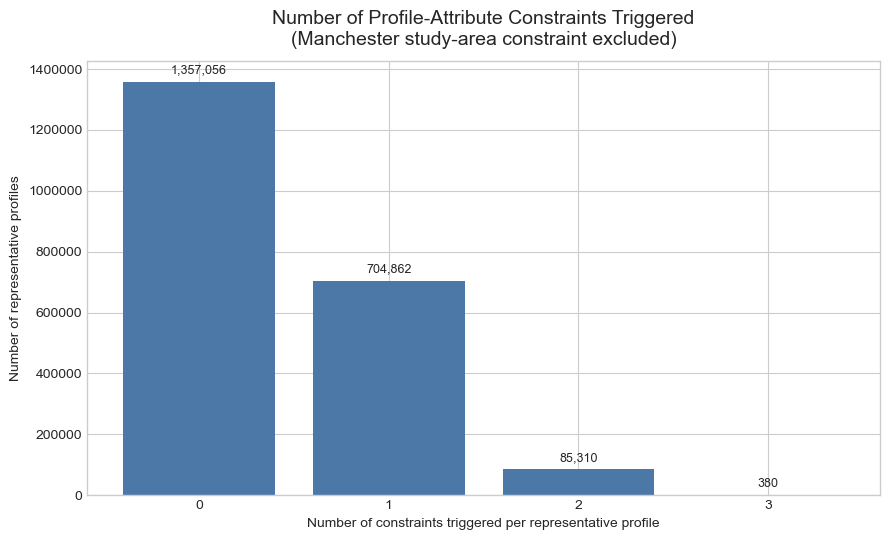

In [10]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Plot and export the number of profiles triggering zero, one or multiple profile-specific constraints.

constraint_count_coverage = (
    profile_validation["Profile-specific constraint count"]
    .value_counts()
    .sort_index()
)

figure, axis = plt.subplots(figsize=(9, 5.5))
bars = axis.bar(
    [str(value) for value in constraint_count_coverage.index],
    constraint_count_coverage.values,
    color="#4C78A8",
)
axis.bar_label(
    bars,
    labels=[f"{int(value):,}" for value in constraint_count_coverage],
    padding=4,
    fontsize=9,
)
axis.set_title(
    "Number of Profile-Attribute Constraints Triggered\n"
    "(Manchester study-area constraint excluded)",
    fontsize=14,
    pad=12,
)
axis.set_xlabel("Number of constraints triggered per representative profile")
axis.set_ylabel("Number of representative profiles")
axis.ticklabel_format(axis="y", style="plain")
figure.tight_layout()

figure_1_path = (
    figure_output_directory
    / "figure_1_constraint_count_coverage.png"
)
figure.savefig(figure_1_path, dpi=300, bbox_inches="tight")
generated_figure_paths.append(figure_1_path)
plt.show()
plt.close(figure)

### Figure 2. Profile without profile-specific constraints

The trip-purpose and start-time distributions are unchanged. The travel-mode distribution differs from the raw source only because the global Manchester condition removes the two London-specific modes and renormalises the remaining probabilities.

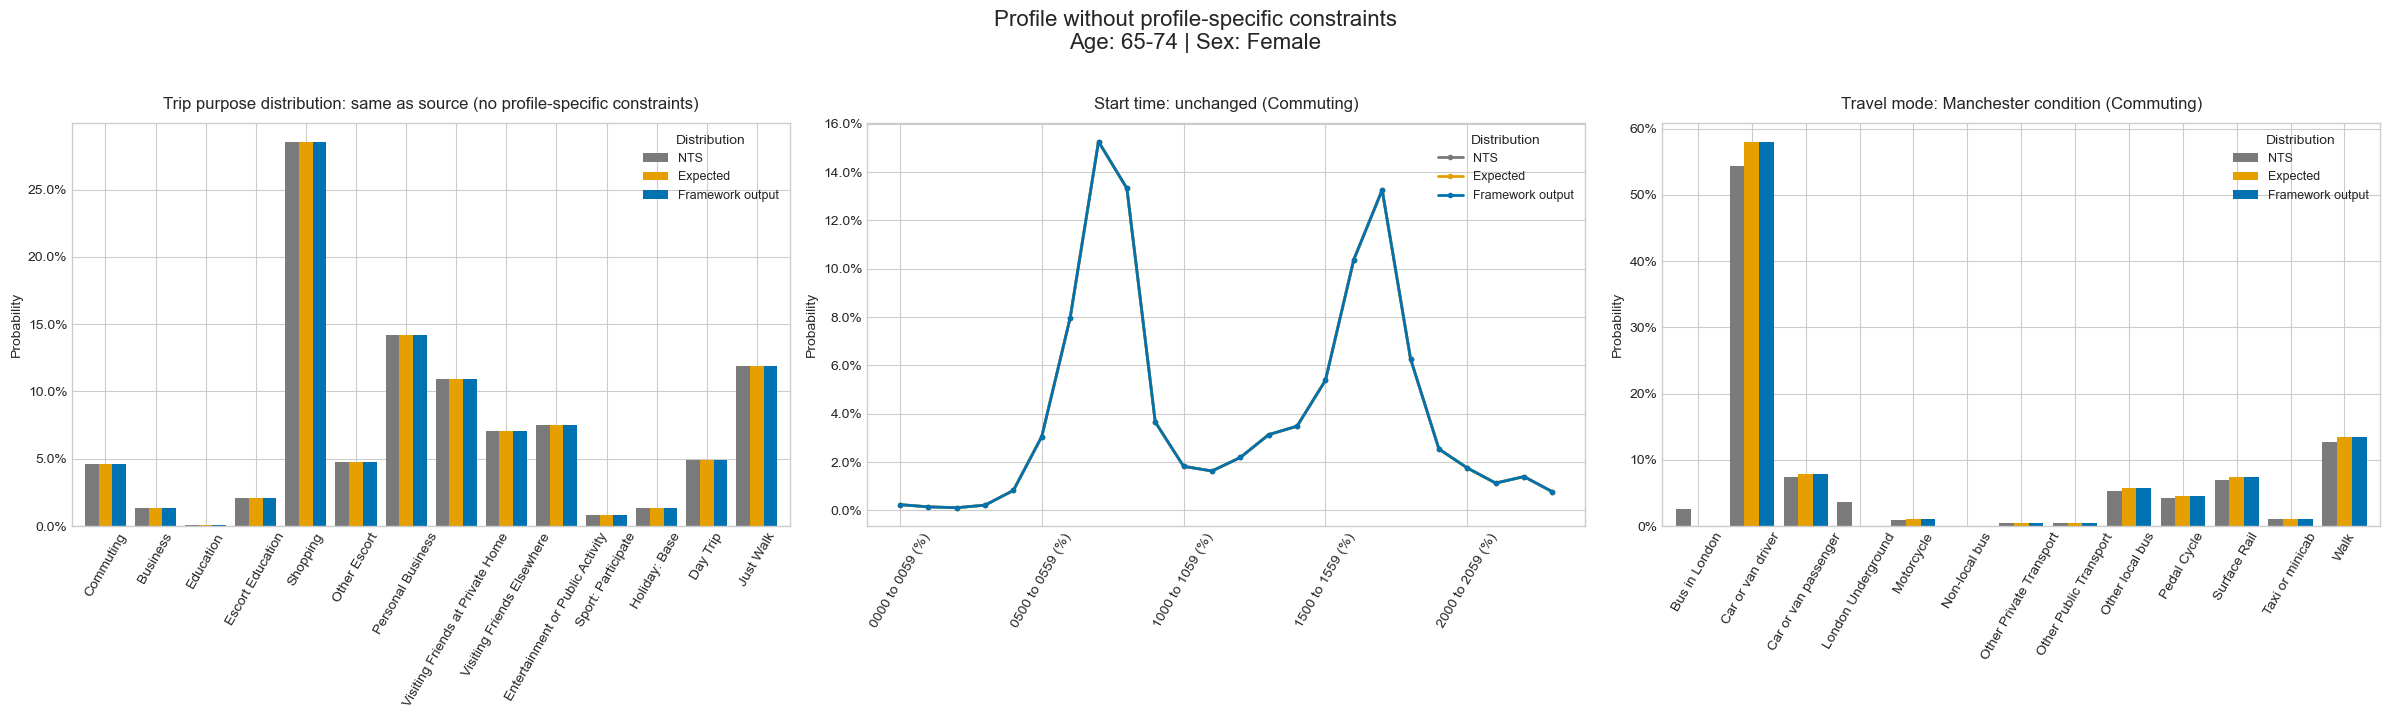

In [11]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Create a three-panel baseline comparison for trip purpose, start time and Manchester-constrained travel mode.

baseline_case_id = select_case(
    case_summary[
        "Profile-specific constraint count"
    ].eq(0),
    prefer_constraint_count=0,
)
baseline_data = plot_data_by_case[baseline_case_id]
baseline_purpose = purpose_with_largest_removed_mode_share(
    baseline_case_id
)
baseline_conditioned = baseline_data["Conditioned"][
    baseline_purpose
]

figure, axes = plt.subplots(1, 3, figsize=(24, 7))
plot_distribution_comparison(
    axes[0],
    baseline_data["Source trip"],
    baseline_data["Expected trip"],
    baseline_data["Framework trip"],
    "Trip purpose distribution: same as source (no profile-specific constraints)",
)
plot_distribution_comparison(
    axes[1],
    baseline_conditioned["Source time"],
    baseline_conditioned["Expected time"],
    baseline_conditioned["Framework time"],
    f"Start time: unchanged ({baseline_purpose})",
    chart_type="line",
)
plot_distribution_comparison(
    axes[2],
    baseline_conditioned["Source mode"],
    baseline_conditioned["Expected mode"],
    baseline_conditioned["Framework mode"],
    f"Travel mode: Manchester condition ({baseline_purpose})",
)
profile = baseline_data["Profile"]
figure.suptitle(
    "Profile without profile-specific constraints\n"
    f"Age: {profile['Age']} | Sex: {profile['Sex']}",
    fontsize=16,
    y=1.02,
)
figure.tight_layout()

figure_2_path = (
    figure_output_directory
    / "figure_2_baseline_distribution_check.png"
)
figure.savefig(figure_2_path, dpi=300, bbox_inches="tight")
generated_figure_paths.append(figure_2_path)
plt.show()
plt.close(figure)

### Figure 3. Individual profile-specific constraint effects

One validated case is selected for each documented rule. Where possible, the notebook prefers a profile triggering only that profile-specific rule. Young profiles necessarily can also trigger the Industry rule; the travel-mode panel isolates and displays the independently expected young-age mode removal.

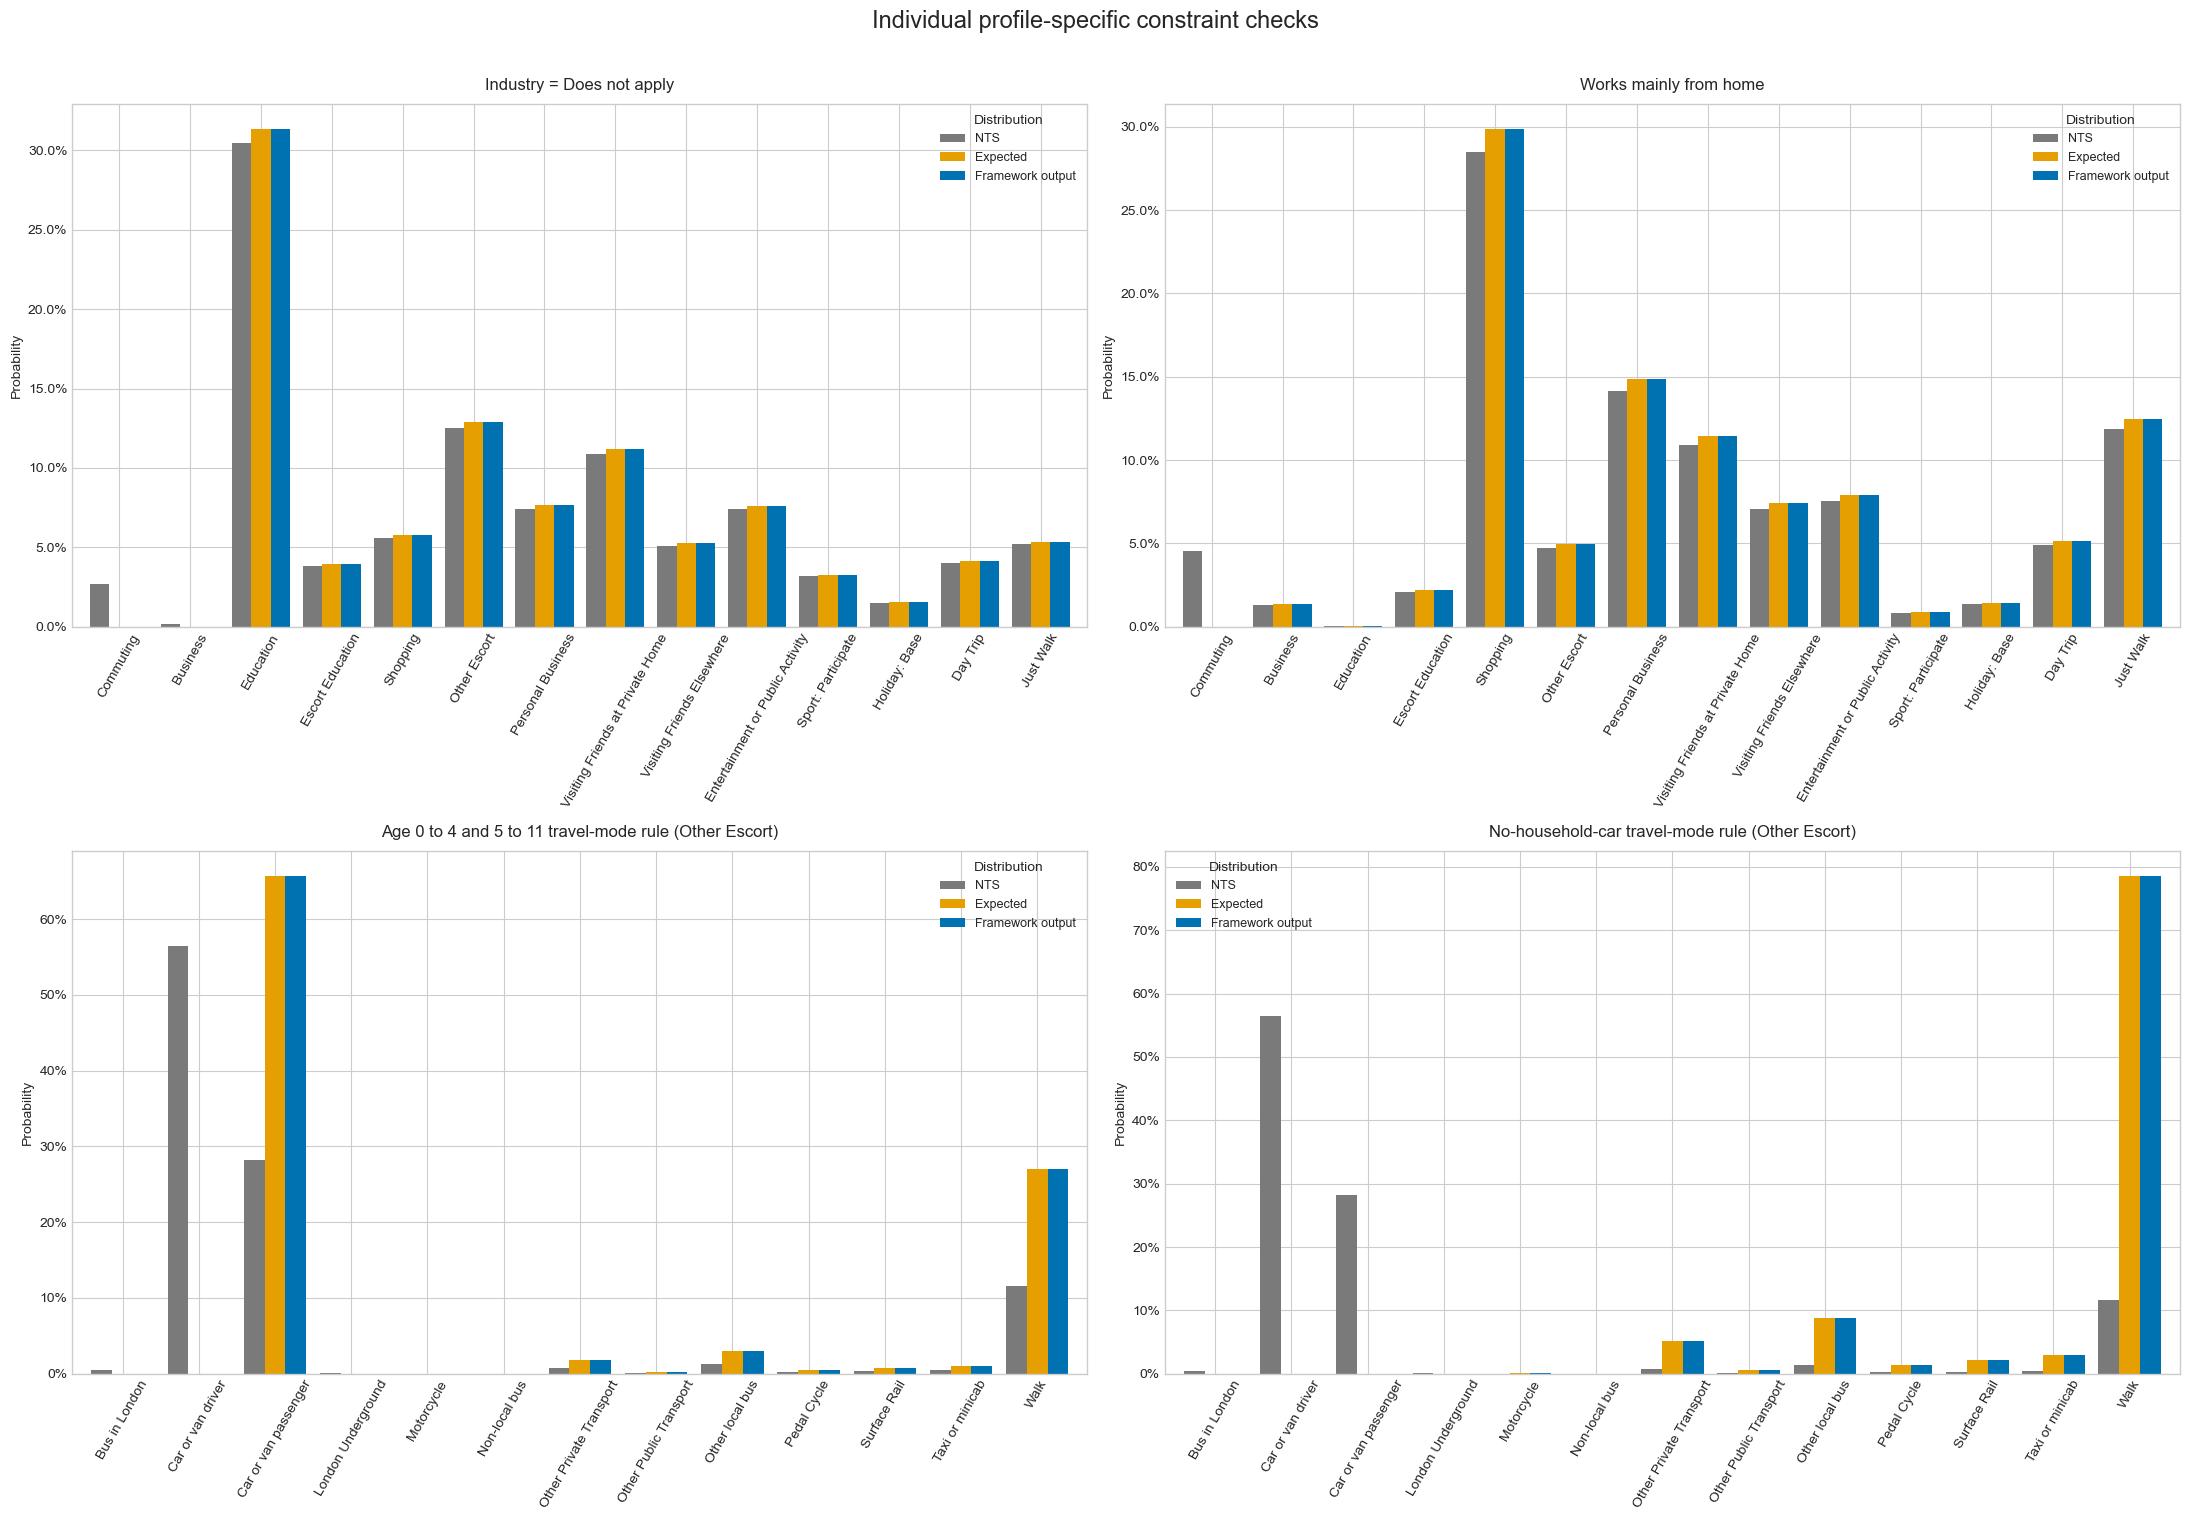

In [12]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Create a four-panel figure for the Industry, WFH, young-age and no-household-car rule effects.

industry_case_id = select_case(
    case_summary["Industry constraint"],
    prefer_constraint_count=1,
)
wfh_case_id = select_case(
    case_summary["WFH constraint"],
    prefer_constraint_count=1,
)
young_case_id = select_case(
    case_summary["Young-age constraint"]
    & ~case_summary["No-car constraint"],
)
no_car_case_id = select_case(
    case_summary["No-car constraint"]
    & ~case_summary["Young-age constraint"],
    prefer_constraint_count=1,
)

industry_data = plot_data_by_case[industry_case_id]
wfh_data = plot_data_by_case[wfh_case_id]
young_data = plot_data_by_case[young_case_id]
no_car_data = plot_data_by_case[no_car_case_id]

young_purpose = purpose_with_largest_removed_mode_share(
    young_case_id
)
no_car_purpose = purpose_with_largest_removed_mode_share(
    no_car_case_id
)

figure, axes = plt.subplots(2, 2, figsize=(22, 15))
plot_distribution_comparison(
    axes[0, 0],
    industry_data["Source trip"],
    industry_data["Expected trip"],
    industry_data["Framework trip"],
    "Industry = Does not apply",
)
plot_distribution_comparison(
    axes[0, 1],
    wfh_data["Source trip"],
    wfh_data["Expected trip"],
    wfh_data["Framework trip"],
    "Works mainly from home",
)
plot_distribution_comparison(
    axes[1, 0],
    young_data["Conditioned"][young_purpose]["Source mode"],
    young_data["Conditioned"][young_purpose]["Expected mode"],
    young_data["Conditioned"][young_purpose]["Framework mode"],
    f"Age 0 to 4 and 5 to 11 travel-mode rule ({young_purpose})",
)
plot_distribution_comparison(
    axes[1, 1],
    no_car_data["Conditioned"][no_car_purpose]["Source mode"],
    no_car_data["Conditioned"][no_car_purpose]["Expected mode"],
    no_car_data["Conditioned"][no_car_purpose]["Framework mode"],
    f"No-household-car travel-mode rule ({no_car_purpose})",
)
figure.suptitle(
    "Individual profile-specific constraint checks",
    fontsize=17,
    y=1.01,
)
figure.tight_layout()

figure_3_path = (
    figure_output_directory
    / "figure_3_individual_constraint_checks.png"
)
figure.savefig(figure_3_path, dpi=300, bbox_inches="tight")
generated_figure_paths.append(figure_3_path)
plt.show()
plt.close(figure)

### Figure 4. Multiple profile-specific constraints

This figure selects a passed case with the largest observed number of profile-specific conditions. It displays the combined trip-purpose effect and the combined travel-mode effect for one retained purpose.

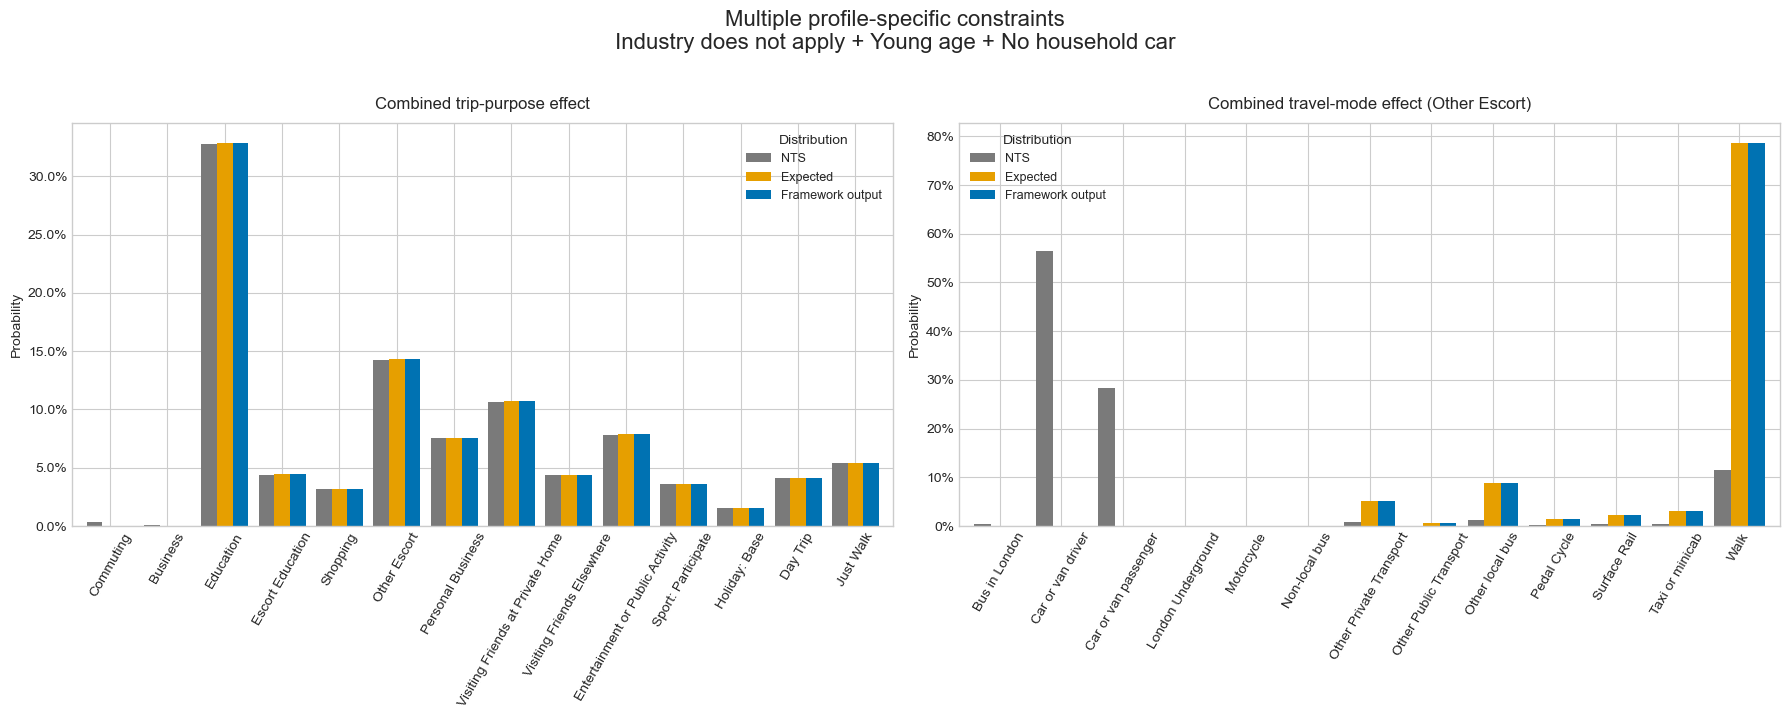

In [13]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Create a two-panel representative comparison showing all applicable trip-purpose and travel-mode removals together.

multiple_candidates = case_summary.loc[
    case_summary[
        "Profile-specific constraint count"
    ].gt(1)
    & case_summary["Validation passed"]
].copy()
if multiple_candidates.empty:
    raise ValueError(
        "No passed multiple-constraint case is available."
    )
multiple_case_id = int(
    multiple_candidates.sort_values(
        [
            "Profile-specific constraint count",
            "Rows represented",
        ],
        ascending=[False, False],
    ).iloc[0]["Validation case"]
)

multiple_data = plot_data_by_case[multiple_case_id]
multiple_purpose = purpose_with_largest_removed_mode_share(
    multiple_case_id
)
multiple_conditioned = multiple_data["Conditioned"][
    multiple_purpose
]

figure, axes = plt.subplots(1, 2, figsize=(18, 7))
plot_distribution_comparison(
    axes[0],
    multiple_data["Source trip"],
    multiple_data["Expected trip"],
    multiple_data["Framework trip"],
    "Combined trip-purpose effect",
)
plot_distribution_comparison(
    axes[1],
    multiple_conditioned["Source mode"],
    multiple_conditioned["Expected mode"],
    multiple_conditioned["Framework mode"],
    f"Combined travel-mode effect ({multiple_purpose})",
)

multiple_case_row = case_summary.loc[
    case_summary["Validation case"].eq(
        multiple_case_id
    )
].iloc[0]
figure.suptitle(
    "Multiple profile-specific constraints\n"
    + multiple_case_row["Constraint combination"],
    fontsize=16,
    y=1.02,
)
figure.tight_layout()

figure_4_path = (
    figure_output_directory
    / "figure_4_multiple_constraint_check.png"
)
figure.savefig(figure_4_path, dpi=300, bbox_inches="tight")
generated_figure_paths.append(figure_4_path)
plt.show()
plt.close(figure)

## 10. Final reproducible result

A complete PASS means:

- all retained rows satisfy the reported demographic constraints;
- all required behavioural conditions occur in the retained profile space;
- every unique output-relevant input combination matches the independently calculated expected distributions;
- every retained row maps to a passed input combination;
- trip-purpose, start-time and travel-mode distributions contain the expected categories, contain finite non-negative probabilities and sum to one; and
- all four explanatory figures were exported after the numerical validation passed.

The validation establishes implementation correctness for the currently implemented rules. It does not establish real-world behavioural accuracy or prove that no additional constraints could be required.

In [14]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Verify all expected figure exports and print a concise final result suitable for the execution record.

expected_figure_names = {
    "figure_1_constraint_count_coverage.png",
    "figure_2_baseline_distribution_check.png",
    "figure_3_individual_constraint_checks.png",
    "figure_4_multiple_constraint_check.png",
}
exported_figure_names = {
    path.name
    for path in generated_figure_paths
    if path.exists() and path.stat().st_size > 0
}

missing_figure_exports = (
    expected_figure_names - exported_figure_names
)
if missing_figure_exports:
    raise AssertionError(
        "Expected figure exports are missing or empty: "
        f"{sorted(missing_figure_exports)}"
    )

print("CONSTRAINT AND DISTRIBUTION VALIDATION: PASS")
print(
    "Retained profile rows covered:",
    f"{len(representative_profile_space):,}",
)
print(
    "Unique behavioural input combinations executed:",
    f"{len(case_summary):,}",
)
print(
    "Figures exported to:",
    figure_output_directory,
)

CONSTRAINT AND DISTRIBUTION VALIDATION: PASS
Retained profile rows covered: 2,147,608
Unique behavioural input combinations executed: 92
Figures exported to: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\constraint_distribution_validation\figures
